In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import random
import torch.optim as optim
import matplotlib.pyplot as plt
import os
from torch.optim.optimizer import Optimizer, required
## two layer neural network
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor
import numpy as np
import matplotlib.pyplot as plt

In [2]:
##

def swish(x):
  return x * F.sigmoid(x)

def snake(x):
  return x + torch.sin(x)**2


class Linear(nn.Module):

    def __init__(self, in_dim, out, bias=False):
        super(Linear, self).__init__()

        #w = torch.zeros(d).normal_()
        self.w = nn.Linear(in_dim, out, bias=False)


    def forward(self, x):
        self.ha = x
        if x.requires_grad:
          self.ha.retain_grad()


        x = self.w(x)
        self.hb = x
        #if x.requires_grad:
        self.hb.retain_grad()
        return x

    def backproj_nobias(self,y):
        # assume no bias

        self.hb.grad=y
        #self.hb.retain_grad()

        x = torch.mm(y,self.w.weight)

        self.ha.grad=x
        #self.ha.retain_grad()

        return x


def mask_processing(x,mask_mode,x_masks):
      if mask_mode==1:
        x_masks.append((F_relu(x)!=0).detach())
      elif mask_mode==2:
        x = x*(x_masks[0].detach())
        x_masks.pop(0)
      return x

# class BiLinear(nn.Module):
#     def __init__(self,in_d,out_d,bias=False):
#         super(Net, self).__init__()
#         self.linear = Linear(in_d,out_d,bias=bias)

#     def forward(self, x):
#         x = self.linear(x)
#         return x

#     def backproj(self,x):
#         pass


class Net(nn.Module):

    def __init__(self, width=10, depth=1,in_d=5,out_d=5, F=F.relu):
        super(Net, self).__init__()

        #w = torch.zeros(d).normal_()
        self.w = Linear(in_d, 200, bias=False)

        self.w2 = Linear(200, 100, bias=False)

        self.w3 = Linear(100, 200, bias=False)
        #self.w.weight.data.normal_(0, 0.5 * d ** -0.5)
        self.u = Linear(200, out_d, bias=False)
        #self.u.weight.data.normal_(0, 0.5 * 1)
        self.h = 0
        self.F = F

    def backproj(self,x,x_masks=None,nonlin=None):
        if x_masks:
          x_masks = list(reversed(x_masks.copy()))
          mask_mode = 2

        x = self.u.backproj_nobias(x)
        if nonlin:
          x = nonlin(x)
        if x_masks:
          x = mask_processing(x,mask_mode,x_masks)

        x = self.w3.backproj_nobias(x)
        if nonlin:
          x = nonlin(x)
        if x_masks:
          x = mask_processing(x,mask_mode,x_masks)

        x = self.w2.backproj_nobias(x)
        if nonlin:
          x = nonlin(x)
        if x_masks:
          x = mask_processing(x,mask_mode,x_masks)

        x = self.w.backproj_nobias(x)

        return x


    def forward(self, x, x_masks=None, nonlin=None):

        if isinstance(x_masks, list):
          if len(x_masks) == 0:
            # if received empty list, fill the list with masks
            mask_mode=1
          else:
            # if received list with elements, use the masks
            # make a clone of it to not modify it
            x_masks=x_masks.copy()
            mask_mode=2
        else:
          # if not received any list, do not use it
          mask_mode=0


        if nonlin:
          used_nonlin = nonlin
        else:
          used_nonlin = self.F

        x = x.view(x.shape[0], -1)

        x = self.w(x)
        x = mask_processing(x,mask_mode,x_masks)
        x = used_nonlin(x)

        x = self.w2(x)
        x = mask_processing(x,mask_mode,x_masks)

        x = used_nonlin(x)
        x = self.w3(x)
        x = mask_processing(x,mask_mode,x_masks)

        x = used_nonlin(x)

        x = self.u(x)


        return x


model = Net()

def F_relu(x):
    return F.relu(x)

def F_identity(x):
    return x


In [4]:
model.w.w.weight.shape


torch.Size([200, 5])

In [5]:
def update_grad_old_autograd(Net1, Net2, X, Y):

          x_masks=[]
          output = Net1(X,x_masks=x_masks)
          output.retain_grad()
          loss = loss_fn(output, Y)
          loss.backward()

          # print(len(x_masks))
          O = output.grad.detach()
          #print(O.shape)
          O2 = Net2(X,x_masks=x_masks)
          loss2 = torch.trace(O.mm(O2.T))
          loss2.backward()
          loss_2_true = loss_fn(O2, Y)
          for t, s in zip(Net1.modules(), Net2.modules()):
            #print(t, s)
            if isinstance(t, Linear):
              #print(1)
              h = t.ha
              gh = s.hb.grad
              #print(h, gh)

              grad = gh.T.mm(h)

              t.w.weight.grad = grad
              #t.w.grad += grad
              s.w.weight.grad = grad

          return loss.item(), loss_2_true.item()


def update_grad(Net1, Net2, X, Y):

          x_masks=[]
          output = Net1(X,x_masks=x_masks)
          output.retain_grad()
          loss = loss_fn(output, Y)
          loss.backward()

          # print(len(x_masks))
          O = output.grad.detach()
          #print(O.shape)
          O2 = Net2(X,x_masks=x_masks)
          loss2 = torch.trace(O.mm(O2.T))
          # loss2.backward()
          loss_2_true = loss_fn(O2, Y)

          In2_backproj = Net2.backproj(O,x_masks=x_masks,nonlin=None)

          for t, s in zip(Net1.modules(), Net2.modules()):
            #print(t, s)
            if isinstance(t, Linear):
              #print(1)
              h = t.ha
              gh = s.hb.grad
              #print(h, gh)

              grad = gh.T.mm(h)

              t.w.weight.grad = grad
              #t.w.grad += grad
              s.w.weight.grad = grad

          return loss.item(), loss_2_true.item()

def mse(Z,Y):
  return ((Z - Y) **2).sum(-1).mean()

In [6]:

noise_range = [0.01]#np.arange(0.1, 5, 0.8)
matrices = []

d = 64

losses = []

loss_fn = mse

for noise in noise_range:

    for lr in [0.005]:
        torch.manual_seed(10)
        print(noise, lr)

        model1 = Net(width=d, depth=1, in_d=d,out_d=d).cuda()
        model2 = Net(width=d, depth=1, in_d=d,out_d=d,F=F_identity).cuda()

        #opt = optim.Adam(model1.parameters(), lr=1e-3, weight_decay=1e-)
        #opt = optim.Adam(model2.parameters(), lr=1e-3, weight_decay=1e-3)
        opt1 = optim.SGD(model1.parameters(), lr=0.1e-1, weight_decay=0.15e-1)#.3e-1)
        opt2 = optim.SGD(model2.parameters(), lr=0.1e-1, weight_decay=0.15e-1)#.3e-1)

        STEP = 10000
        #criterion = F.mse_loss
        #sum_loss = 0

        W = torch.zeros(d, d).cuda().normal_()
        W[d//2:] *= 0

        for i in range(STEP):


          N = 100
          X = torch.zeros([N, d]).normal_(0,1).cuda()#* torch.Tensor(np.arange(0.01, 2.01, 2 / d)).cuda()

          eps = noise * torch.zeros([N, d]).normal_(0,1).cuda()#* torch.Tensor(np.arange(0.01, 2.01, 2 / d)).cuda()
          #eps[2:] = 0


          Y =  X + eps.mm(W) #* mask #.mean(dim=1, keepdim=True) #+ eps
          #print(X.shape, Y.shape)

          opt1.zero_grad()
          opt2.zero_grad()




          #print(output.shape, Y.shape)
          loss, loss_2_true = update_grad(model1, model2, X, Y)


          if False:
            loss = ((output - Y) **2).sum(-1).mean()
            loss.backward()

            O = output.grad.detach()
            #print(O.shape)
            O2 = model2(X)
            loss2 = torch.trace(O.mm(O2.T))
            loss2.backward()
            for t, s in zip(model1.modules(), model2.modules()):
              #print(t, s)
              if isinstance(t, Linear):
                #print(1)
                h = t.ha
                gh = s.hb.grad
                #print(h, gh)

                grad = gh.T.mm(h)

                t.w.weight.grad = grad
                #t.w.grad += grad
                s.w.weight.grad = grad
          torch.nn.utils.clip_grad_norm_(model2.parameters(), 10)
          torch.nn.utils.clip_grad_norm_(model1.parameters(), 10)


          #for t, s in zip(model1.modules(), model2.modules()):
            #print(t, s)
          #    if isinstance(t, Linear):
           #     print(t.w.weight.grad.norm())
          #      print(s.w.weight.grad.norm())
              #t.w.grad += grad
              #s.w.weight.grad = grad

          #print(loss.item())

          #print(O2.shape, O.shape)
          losses.append([loss, loss_2_true])

          if i % 30 ==0:
            print(loss, loss_2_true)

          opt1.step()
          opt2.step()
            #with torch.no_grad():


0.01 0.005


/opt/amdgpu/share/libdrm/amdgpu.ids: No such file or directory


65.35823822021484 65.2677230834961
63.26798629760742 63.38949203491211
63.3557014465332 63.86199188232422
64.40113830566406 65.77484893798828
61.24508285522461 64.0810317993164
60.040916442871094 64.56753540039062
53.29528045654297 60.453125
50.950809478759766 61.09603500366211
48.79513168334961 59.86908721923828
45.708534240722656 60.28657913208008
41.695213317871094 57.06282043457031
42.26909637451172 61.31684494018555
37.66402816772461 56.47590637207031
38.72089385986328 60.66921615600586
37.8560676574707 63.50041961669922
36.391326904296875 62.258689880371094
35.98757553100586 63.5898323059082
34.2381706237793 61.94685363769531
33.99705505371094 64.66637420654297
33.17890167236328 65.5628890991211
32.16261672973633 66.91407012939453
30.42701530456543 66.25667572021484
29.918066024780273 67.42084503173828
29.49289321899414 65.21552276611328
30.273406982421875 68.85060119628906
28.9139347076416 67.13519287109375
27.876447677612305 65.84850311279297
26.215341567993164 67.05517578125
2

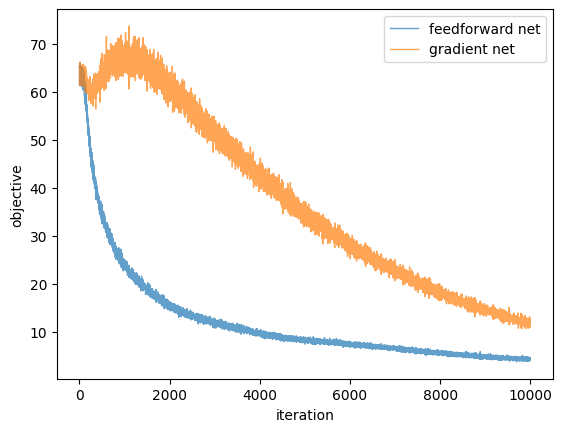

In [7]:
losses = np.array(losses)
plt.plot(losses[:,0], alpha=0.7, lw=1, label='feedforward net')
plt.plot(losses[:,1], alpha=0.7, lw=1, label='gradient net')
plt.ylabel('objective')
plt.xlabel('iteration')
plt.legend()
#plt.loglog()

In [ ]:
### mnist

In [8]:
training_data = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.MNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

100%|██████████| 9.91M/9.91M [00:18<00:00, 542kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 254kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.27MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.18MB/s]


In [9]:
batch_size = 256

# Create data loaders.
train_dataloader = DataLoader(training_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of X [N, C, H, W]: torch.Size([256, 1, 28, 28])
Shape of y: torch.Size([256]) torch.int64


In [10]:
#loss_fn = nn.MSELoss()
device = 'cuda'
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

def converter(indices):
    '''
    convert indices to one-hot encoding
    '''
    probvec = torch.zeros(len(indices), 10)
    for number, index in enumerate(indices):
      probvec[number][index] = 1.0
    return probvec

def train(dataloader, model1, model2, loss_fn, opt1, opt2):
    global losses
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        y = converter(y)
        X, y = X.to(device), y.to(device)

        # Compute prediction error
        #pred = model(X)
        #loss = loss_fn(pred, y)
        opt1.zero_grad()
        opt2.zero_grad()
        loss, loss2 = update_grad(model1, model2, X, y)

        # Backpropagation

        opt1.step()
        opt2.step()

        if batch % 50 == 0:
            #loss, current = loss.item(), batch * len(X)
            print(loss, loss2)
        losses.append([loss, loss2])

def test(dataloader, model, loss_fn,nonlin=None):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    #model.eval()
    test_loss, correct = 0, 0
    #with torch.no_grad():
    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        pred = model(X,nonlin=nonlin)
        #test_loss += loss_fn(pred, converter(y)).item()
        correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [12]:
epochs = 10
## model1 is the feedforward, model2 is the gradient net

model1 = Net(in_d=784,out_d=10).cuda()
model2 = Net(in_d=784,out_d=10,F=F_identity).cuda()
opt1 = optim.SGD(model1.parameters(), lr=0.5e-1, weight_decay=0.001, momentum=0.9)#.3e-1)
opt2 = optim.SGD(model2.parameters(), lr=0.5e-1, weight_decay=0.001, momentum=0.9)#.3e-1)

losses =[]

for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model1, model2, loss_fn, opt1, opt2)
    test(test_dataloader, model1, loss_fn)
    test(test_dataloader, model2, loss_fn, nonlin=F_relu)

print("Done!")

Epoch 1
-------------------------------
2.3022615909576416 2.305124521255493
2.1297144889831543 2.006453275680542
0.6329973936080933 0.6409623026847839
0.40357881784439087 0.547263503074646
0.3156306743621826 0.32893407344818115
Test Error: 
 Accuracy: 91.1%, Avg loss: 0.000000 

Test Error: 
 Accuracy: 88.9%, Avg loss: 0.000000 

Epoch 2
-------------------------------
0.29634803533554077 0.32089126110076904
0.283230721950531 0.3488031327724457
0.2475527822971344 0.27409857511520386
0.188666433095932 0.25130245089530945
0.1497032344341278 0.1554715782403946
Test Error: 
 Accuracy: 94.5%, Avg loss: 0.000000 

Test Error: 
 Accuracy: 94.0%, Avg loss: 0.000000 

Epoch 3
-------------------------------
0.16662341356277466 0.1869676411151886
0.15425679087638855 0.19411881268024445
0.1970360428094864 0.24380716681480408
0.11999163031578064 0.14852996170520782
0.12042810767889023 0.1260855495929718
Test Error: 
 Accuracy: 96.4%, Avg loss: 0.000000 

Test Error: 
 Accuracy: 95.9%, Avg loss: 0

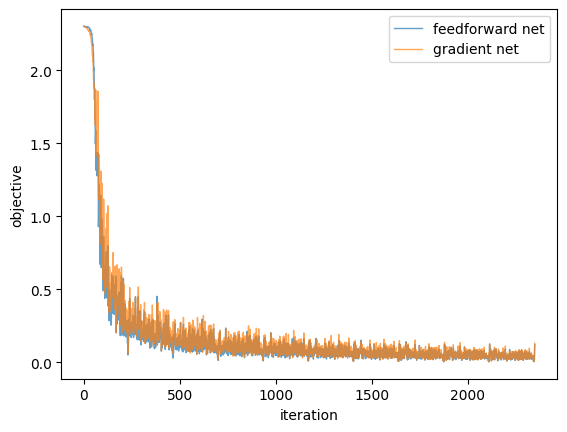

In [13]:
losses = np.array(losses)
plt.plot(losses[:,0], alpha=0.7, lw=1, label='feedforward net')
plt.plot(losses[:,1], alpha=0.7, lw=1, label='gradient net')
plt.ylabel('objective')
plt.xlabel('iteration')
plt.legend()
#plt.loglog()

In [14]:
losses

array([[2.30226159, 2.30512452],
       [2.30021095, 2.30482054],
       [2.29991484, 2.30429697],
       ...,
       [0.01508891, 0.01507278],
       [0.08088949, 0.08981974],
       [0.12294136, 0.13037318]], shape=(2350, 2))